# Borrower Segmentation: RFM + K-means

**Goal:** group applicants by their prior borrowing behaviour, then check whether
the groups differ in default, income and delinquency.

**RFM, adapted for lending** (features from `metrics.borrower_rfm`, built on
*approved* prior loans):

| Feature | Meaning |
|---|---|
| Recency | days since the most recent approved prior loan, relative to the current application |
| Frequency | number of approved prior loans |
| Monetary | total credit amount across approved prior loans |

**Method decisions**
- Applicants with no approved prior loan have no behaviour to cluster. They get their own rule-based segment.
- Default, income and age are used only to **profile** segments, never to build them. This keeps segments behavioural and avoids leakage.
- K-means is distance-based and sensitive to scale and outliers, so features are capped at the 1st and 99th percentiles, log-transformed and standardised.
- Dates are relative offsets, so recency means "before the current application", not calendar time.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ACCENT = "#2F7A5C"
AMBER = "#9C7325"
RANDOM_STATE = 42


In [2]:
load_dotenv(override=True)

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.environ.get("DB_USER"),
    password=os.environ.get("DB_PASS"),
    host=os.environ.get("DB_HOST", "localhost"),
    port=int(os.environ.get("DB_PORT", "5432")),
    database=os.environ.get("DB_NAME"),
)
engine = create_engine(connection_url)


## 1. Load features and profiling context

In [3]:
rfm = pd.read_sql("SELECT * FROM metrics.borrower_rfm;", engine)

# Context used ONLY for profiling segments after clustering
ctx = pd.read_sql("""
    SELECT sk_id_curr, target, amt_income_total, age_years, employment_years
    FROM staging.stg_application;
""", engine)

dpd = pd.read_sql("""
    SELECT sk_id_curr, ever_30_plus_any_loan, worst_dpd_any_loan
    FROM metrics.borrower_level_dpd;
""", engine)

df = rfm.merge(ctx, on="sk_id_curr", how="left").merge(dpd, on="sk_id_curr", how="left")
df["has_history"] = df["frequency"] > 0

print(f"Applicants: {len(df):,}")
print(f"No approved prior loan: {(~df['has_history']).sum():,} ({(~df['has_history']).mean():.1%})")
df.loc[df["has_history"], ["recency_days", "frequency", "monetary"]].describe(percentiles=[0.5, 0.9, 0.99])


Applicants: 307,511
No approved prior loan: 17,446 (5.7%)


,recency_days,frequency,monetary
count,"290,065.00","290,065.00","290,065.00"
mean,603.06,3.05,"615,931.07"
std,564.02,2.12,"764,590.24"
min,1.00,1.00,0.00
50%,434.00,3.00,"318,168.00"
90%,"1,319.00",6.00,"1,584,555.30"
99%,"2,658.00",10.00,"3,564,062.46"
max,"2,922.00",27.00,"10,486,021.50"


Among the 290,065 applicants with at least one approved prior loan, half have taken 3 or fewer loans, and half have borrowed 318,168 or less in total across them.

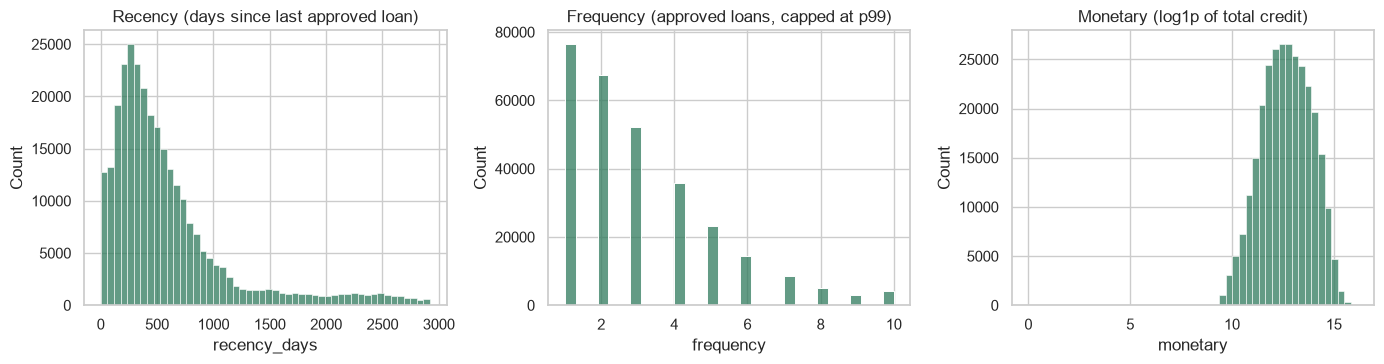

In [4]:
hist = df[df["has_history"]].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(hist["recency_days"], bins=50, ax=axes[0], color=ACCENT)
axes[0].set_title("Recency (days since last approved loan)")
sns.histplot(hist["frequency"].clip(upper=hist["frequency"].quantile(0.99)), bins=30, ax=axes[1], color=ACCENT)
axes[1].set_title("Frequency (approved loans, capped at p99)")
sns.histplot(np.log1p(hist["monetary"]), bins=50, ax=axes[2], color=ACCENT)
axes[2].set_title("Monetary (log1p of total credit)")
plt.tight_layout()
plt.show()


All three features are right-skewed, The next step caps and log-transforms them before clustering.

## 2. Prepare features

In [5]:

features = ["recency_days", "frequency", "monetary"]
X = hist[features].copy()

# Cap at the 1st and 99th percentiles so a few extreme borrowers cannot pull cluster centres
caps = X.quantile([0.01, 0.99])
X = X.clip(lower=caps.loc[0.01], upper=caps.loc[0.99], axis=1)

# Log-transform the skewed variables, then standardise
X_log = np.log1p(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

caps


,recency_days,frequency,monetary
0.01,15.00,1.00,"20,259.00"
0.99,"2,658.00",10.00,"3,564,062.46"


### 3. Choose the number of clusters 

**TO DO:**

- Fit k-means for every k from 2 to 8, scores each fit two ways, and collects the scores in a table. 
- Use the table to choose K.

In [6]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_scaled), size=min(20000, len(X_scaled)), replace=False)

results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    sil = silhouette_score(X_scaled[sample_idx], model.labels_[sample_idx])
    results.append({"k": k, "inertia": model.inertia_, "silhouette": sil})

k_scores = pd.DataFrame(results)
k_scores


,k,inertia,silhouette
0,2,"475,950.47",0.38
1,3,"371,920.50",0.35
2,4,"300,094.81",0.30
3,5,"253,630.71",0.28
4,6,"225,127.78",0.28
5,7,"203,034.37",0.27
6,8,"186,661.59",0.27


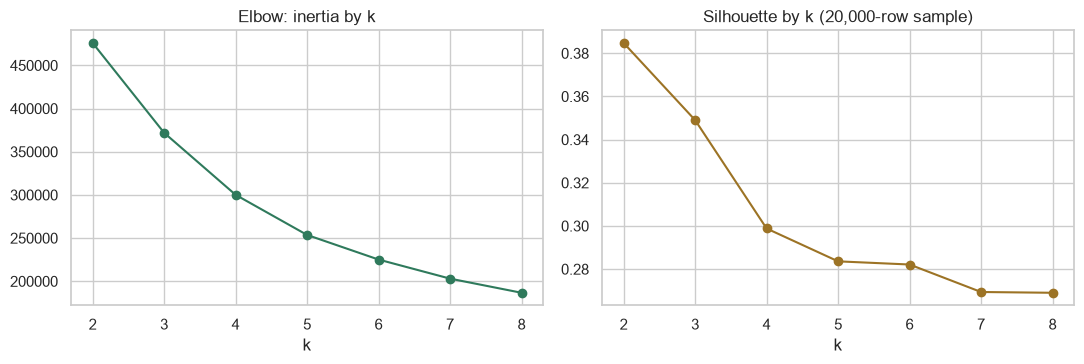

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_scores["k"], k_scores["inertia"], marker="o", color=ACCENT)
axes[0].set_title("Elbow: inertia by k")
axes[0].set_xlabel("k")
axes[1].plot(k_scores["k"], k_scores["silhouette"], marker="o", color=AMBER)
axes[1].set_title("Silhouette by k (20,000-row sample)")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()


The elbow shows no sharp break, only a gentle bend around 4 to 5. Silhouette falls from about 0.38 at k=2 and flattens at about 0.28 from k=5 onward, so adding clusters beyond 5 gains little.

## 4. Fit the final model and check stability

In [11]:
K = 5  

km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
hist["segment_id"] = km.labels_

# Stability: a second run with a different seed should find nearly the same segments
km_check = KMeans(n_clusters=K, n_init=20, random_state=7).fit(X_scaled)
ari = adjusted_rand_score(km.labels_, km_check.labels_)
print(f"Adjusted Rand Index between two seeds: {ari:.3f}  (1.0 = identical segments)")


Adjusted Rand Index between two seeds: 0.976  (1.0 = identical segments)


The value of 0.976 is near 1 which means the segments are stable. A silhouette near 0.28 signals weak natural structure: the segments partition a continious borrowing behaviour rather than reveal distinct groups, This means they are practical tiers.

## 5. Profile the segments

In [12]:
overall_default = df["target"].mean() * 100

profile = hist.groupby("segment_id").agg(
    borrowers=("sk_id_curr", "count"),
    median_recency_days=("recency_days", "median"),
    median_frequency=("frequency", "median"),
    median_monetary=("monetary", "median"),
    median_income=("amt_income_total", "median"),
    median_age=("age_years", "median"),
    default_rate_pct=("target", lambda s: s.mean() * 100),
    ever_30_plus_pct=("ever_30_plus_any_loan", lambda s: s.dropna().astype(float).mean() * 100),
)
profile["share_pct"] = profile["borrowers"] / profile["borrowers"].sum() * 100

no_hist_default = df.loc[~df["has_history"], "target"].mean() * 100
print(f"Overall default rate: {overall_default:.2f}%")
print(f"No-prior-history group default rate: {no_hist_default:.2f}%")
profile.round(2)


Overall default rate: 8.07%
No-prior-history group default rate: 6.11%


,borrowers,median_recency_days,median_frequency,median_monetary,median_income,median_age,default_rate_pct,ever_30_plus_pct,share_pct
segment_id,,,,,,,,,
0,33185,83.00,3.00,"399,352.50","144,000.00",41.00,8.20,6.16,11.44
1,64675,380.00,1.00,"118,611.00","135,000.00",40.40,9.57,2.35,22.30
2,85182,509.00,3.00,"443,889.00","157,500.00",43.40,7.69,7.42,29.37
3,61677,344.00,5.00,"1,369,183.50","157,500.00",46.30,6.98,8.74,21.26
4,45346,"1,485.00",1.00,"80,520.75","135,000.00",43.20,8.82,7.62,15.63


Frequency groups the segments into three levels (1, 3 and 5 prior loans), and recency and total credit separate the segments within a level. Median income (135,000 to 157,500) and age (40 to 46) differ only modestly across segments, so they describe the segments without defining them.

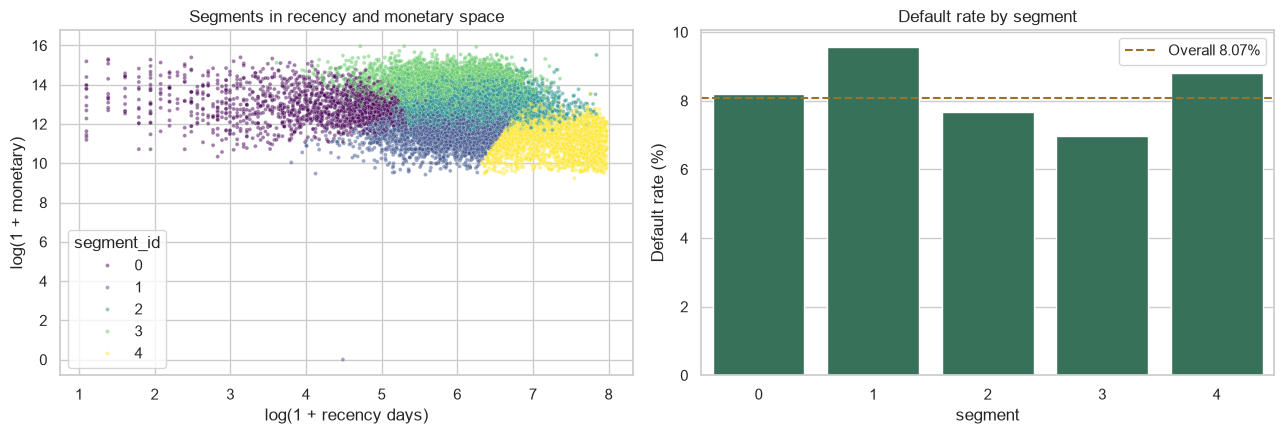

In [13]:
plot_df = hist.sample(n=min(15000, len(hist)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(
    data=plot_df, x=np.log1p(plot_df["recency_days"]), y=np.log1p(plot_df["monetary"]),
    hue="segment_id", palette="viridis", s=8, alpha=0.5, ax=axes[0],
)
axes[0].set_xlabel("log(1 + recency days)")
axes[0].set_ylabel("log(1 + monetary)")
axes[0].set_title("Segments in recency and monetary space")

rates = profile["default_rate_pct"].reset_index()
sns.barplot(data=rates, x="segment_id", y="default_rate_pct", color=ACCENT, ax=axes[1])
axes[1].axhline(overall_default, color=AMBER, linestyle="--", label=f"Overall {overall_default:.2f}%")
axes[1].set_title("Default rate by segment")
axes[1].set_xlabel("segment")
axes[1].set_ylabel("Default rate (%)")
axes[1].legend()
plt.tight_layout()
plt.show()


 Segments were built with k-means on three features, measured relative to the current application: recency (days since the borrower's most recent approved prior loan), frequency (number of approved prior loans) and monetary (total credit across those loans).

The scatter plot shows a random sample of 15,000 borrowers in recency and monetary space, on a log scale. Segment 0 holds the most recently active borrowers (median 83 days). Segment 4 holds the longest-lapsed, lowest-value borrowers (median 1,485 days, 80,521 total credit). Segment 3 holds the highest-value borrowers (median total credit 1.37 million). The segments form adjacent regions of one continuous cloud with no gaps between them, which fits the weak cluster structure (silhouette about 0.28). Frequency is not plotted, and it separates some adjacent segments further, for example segments 0 and 1 (median 3 and 1 prior loans).



# Deep dive on the connection between income level and the segments

income_band  Q1 (lowest)    Q2    Q3  Q4 (highest)
segment_id                                        
0                  33.20 17.70 28.00         21.00
1                  39.70 17.80 24.60         17.90
2                  31.10 17.20 27.30         24.40
3                  24.30 16.50 29.80         29.50
4                  38.30 17.60 24.90         19.20


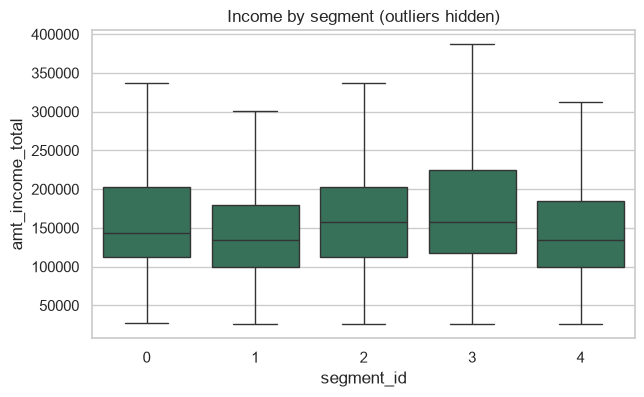

In [14]:
hist["income_band"] = pd.qcut(hist["amt_income_total"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
share = pd.crosstab(hist["segment_id"], hist["income_band"], normalize="index") * 100
print(share.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=hist, x="segment_id", y="amt_income_total", showfliers=False, color=ACCENT, ax=ax)
ax.set_title("Income by segment (outliers hidden)")
plt.show()

Income differs modestly across the segments. Median income is 157,500 in segments 2 and 3, 144,000 in segment 0 and 135,000 in segments 1 and 4, and the interquartile ranges overlap heavily, so income describes the segments without defining them. Against the overall income mix, segment 3 leans toward the top quartile (+6.6 points) and segment 1 toward the bottom (+6.8 points in the lowest quartile). Ranking the segments by default rate, lowest to highest, gives 3, 2, 0, 4, 1, the same order as their top-quartile tilt. The two move together across the five segments, but this does not show that income explains the default gaps.

## 6. Name the segments and save them

In [15]:
# Fill in after reading the profile table, for example:
# SEGMENT_NAMES = {0: "Dormant, low value", 1: "Active, high value"}
SEGMENT_NAMES = {}

hist["segment_name"] = hist["segment_id"].map(SEGMENT_NAMES).fillna("Segment " + hist["segment_id"].astype(str))

no_hist = df.loc[~df["has_history"], ["sk_id_curr"]].assign(segment_id=-1, segment_name="No prior loan history")
segments = pd.concat([hist[["sk_id_curr", "segment_id", "segment_name"]], no_hist], ignore_index=True)

assert segments["sk_id_curr"].is_unique
assert len(segments) == len(df)
segments["segment_name"].value_counts().sort_values(ascending=False)

C:\Users\MoteTheAnalyst\AppData\Local\Temp\ipykernel_15000\2315125738.py:5: Pandas4Warning: 'StringArray' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  hist["segment_name"] = hist["segment_id"].map(SEGMENT_NAMES).fillna("Segment " + hist["segment_id"].astype(str))


segment_name
Segment 2                85182
Segment 1                64675
Segment 3                61677
Segment 4                45346
Segment 0                33185
No prior loan history    17446
Name: count, dtype: int64

### Default Rates across the segments, and  vs Overall default rates

In [16]:
seg_default = (
    segments.merge(df[["sk_id_curr", "target"]], on="sk_id_curr")
    .groupby(["segment_id", "segment_name"])
    .agg(
        borrowers=("target", "size"),
        defaults=("target", "sum"),
        default_rate_pct=("target", lambda s: s.mean() * 100),
    )
    .reset_index()
)

overall = df["target"].mean() * 100
seg_default["vs_overall_pts"] = seg_default["default_rate_pct"] - overall

# 95% margin of error for a proportion, in percentage points
p = seg_default["default_rate_pct"] / 100
seg_default["moe_pts"] = 1.96 * np.sqrt(p * (1 - p) / seg_default["borrowers"]) * 100

print(f"Overall default rate: {overall:.2f}%")
seg_default.round(2)

Overall default rate: 8.07%


,segment_id,segment_name,borrowers,defaults,default_rate_pct,vs_overall_pts,moe_pts
0,-1,No prior loan history,17446,"1,066.00",6.11,-1.96,0.36
1,0,Segment 0,33185,"2,720.00",8.20,0.12,0.30
2,1,Segment 1,64675,"6,190.00",9.57,1.50,0.23
3,2,Segment 2,85182,"6,547.00",7.69,-0.39,0.18
4,3,Segment 3,61677,"4,302.00",6.98,-1.10,0.20
5,4,Segment 4,45346,"4,000.00",8.82,0.75,0.26


## Findings

K-means grouped the 290,065 applicants with at least one approved prior loan into five segments (0 to 4). The 17,446 applicants with no approved prior loan form a sixth, rule-based group. The overall default rate is 8.07%.

| Segment | Borrowers | Default rate | vs overall (pts) | Median approved prior loans | Borrowers ever 30+ late(%) |
|---|---:|---:|---:|---:|---:|
| 3 | 61,677 | 6.98% | −1.09 | 5 | 8.74 |
| 2 | 85,182 | 7.69% | −0.39 | 3 | 7.42 |
| 0 | 33,185 | 8.20% | +0.12 | 3 | 6.16 |
| 4 | 45,346 | 8.82% | +0.75 | 1 | 7.62 |
| 1 | 64,675 | 9.57% | +1.50 | 1 | 2.35 |
| No prior loan history | 17,446 | 6.11% | −1.96 | NA | NA |

**Key points**

- **Default rates range from 6.98% to 9.57% across the five segments.** Segment 1 defaults at about 1.4 times the rate of segment 3, a gap of 2.59 points.
- **Segment 3 is the lowest-risk behavioural segment and segment 1 the highest.** Segments 2 and 4 sit clearly below and above the portfolio rate. Segment 0 is in line with it, because its +0.12 gap is smaller than the margin of error (about ±0.2 to ±0.4 points at these sizes).
- **Applicants with no approved prior loan default least (6.11%).** This group mixes first-time applicants with applicants whose earlier applications were all refused or cancelled, so it doesn't isolate either one.


**Limits**

- Segments describe prior borrowing behaviour. A difference in default rate shows an association, not a cause.
- Recency uses relative offsets, not calendar dates.
- K-means found weak structure (silhouette about 0.28), so treat the segments as practical tiers, not distinct groups.




In [19]:
# One row per applicant. Relate to stg_application on sk_id_curr in Power BI (one-to-one).
segments.to_sql(
    "borrower_segments", engine, schema="metrics",
    if_exists="replace", index=False, chunksize=10000, method="multi",
)
print("Saved metrics.borrower_segments:", len(segments), "rows")


Saved metrics.borrower_segments: 307511 rows
